# Materi 4 — Langkah Praktis Menyusun Laporan Analisis Cerdas secara Otomatis
**Pelatihan Gen AI Integrated Data Science**

---

## Tujuan pembelajaran
1. Menyusun alur **6 langkah** laporan otomatis: *Tarik data → Hitung KPI → Deteksi anomali → Susun fakta → Narasi AI → Dokumen & distribusi*.
2. Menghitung KPI standar: **pencapaian target, MoM, YoY, kontribusi (Pareto)**.
3. Mendeteksi **anomali** secara statistik (z-score) agar laporan fokus pada hal yang tidak biasa.
4. Menulis narasi dengan LLM yang **terikat pada fakta** (*grounded*) dan **memverifikasi angka** secara otomatis.
5. Menghasilkan **laporan Word + lampiran Excel + draf email** dengan satu fungsi yang siap dijadwalkan.

## Studi kasus
Setiap awal bulan, tim Sales Planning menyusun *Laporan Kinerja Penjualan Bulanan* untuk manajemen. Secara manual prosesnya 1–2 hari. Kita otomatiskan menjadi hitungan detik, dengan kualitas angka yang **lebih terjamin**.

```
 ① Tarik data ─► ② KPI ─► ③ Anomali ─► ④ Fakta (JSON) ─► ⑤ Narasi LLM ─► ⑥ Word/Excel/Email
                                                                 ▲
                                            Verifikasi angka otomatis (anti-halusinasi)
```
> **Prinsip utama: angka dihitung Python, kata ditulis AI, keputusan diambil manusia.**

## Langkah 0 — Library
| Library | Kegunaan |
|---|---|
| `pandas`, `numpy` | Data, KPI, statistik |
| `matplotlib` | Grafik untuk laporan (disimpan sebagai PNG) |
| `docx` (*python-docx*) | Membuat dokumen Word (.docx) |
| `openpyxl` | *Engine* untuk menulis Excel (.xlsx) dari pandas |
| `email.message` | Menyusun draf email beserta lampiran |

Jika memakai Google Colab, jalankan dulu: `!pip install python-docx openpyxl`

In [1]:
import os, re
from email.message import EmailMessage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from docx import Document
from docx.shared import Pt, Cm, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH

MERAH, GELAP, ABU = "#C8102E", "#1F2A37", "#8A94A6"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})

**Penjelasan kode**
- `from docx import Document` — kelas utama python-docx untuk membuat/membuka dokumen Word. `Pt`, `Cm` adalah satuan ukuran; `RGBColor` untuk warna teks; `WD_ALIGN_PARAGRAPH` untuk perataan.
- `MERAH, GELAP, ABU` — palet warna konsisten untuk semua grafik laporan (identitas visual).
- `plt.rcParams.update({...})` — menghilangkan garis bingkai atas & kanan grafik agar tampak bersih.

## Langkah ① — Tarik data
Di produksi, langkah ini berupa query ke *data warehouse* (`pd.read_sql`) atau membaca file ekspor sistem. Di sini kita membangkitkan data penjualan bulanan **Jan 2025 – Sep 2026** per wilayah × model, lengkap dengan target. Dua **anomali** ditanam di September 2026.

In [15]:
rng = np.random.default_rng(2026)
WILAYAH = {"Jabodetabek": 1.00, "Jawa Barat": 0.85, "Jawa Timur": 0.80, "Jawa Tengah": 0.70,
           "Sumatera": 0.55, "Kalimantan": 0.30}                       # skala pasar relatif
MODEL = {"BeAT": (5200, 19.0), "Vario 125": (3100, 24.5), "Scoopy": (1900, 23.0),
         "PCX 160": (1100, 34.0), "ADV 160": (650, 37.0), "CBR150R": (420, 38.0), "Supra X 125": (900, 20.5)}
BULAN = pd.date_range("2025-01-01", "2026-09-01", freq="MS")            # awal setiap bulan
MUSIM = {1: .92, 2: .95, 3: 1.18, 4: 1.05, 5: .98, 6: 1.02, 7: 1.00, 8: 1.00, 9: .97, 10: 1.00, 11: .98, 12: 1.06}

baris = []
for b in BULAN:
    tren = 1 + 0.004 * ((b.year - 2025) * 12 + b.month - 1)            # pertumbuhan ±0,4%/bulan
    for w, sw in WILAYAH.items():
        for m, (dasar, harga_juta) in MODEL.items():
            harapan = dasar * sw * MUSIM[b.month] * tren
            unit = harapan * rng.normal(1, 0.05)
            baris.append({"bulan": b, "wilayah": w, "model": m, "unit": unit,
                          "target_unit": round(harapan * 1.03, -1), "harga_juta": harga_juta})
data = pd.DataFrame(baris)

# --- menanam 2 anomali pada September 2026 ---
sep = data["bulan"] == "2026-09-01"
data.loc[sep & (data["wilayah"] == "Kalimantan") & (data["model"] == "PCX 160"), "unit"] *= 0.55
data.loc[sep & (data["wilayah"] == "Jawa Barat") & (data["model"] == "Vario 125"), "unit"] *= 1.40

data["unit"] = data["unit"].round().astype(int)
data["pendapatan_juta"] = data["unit"] * data["harga_juta"]
print(data.shape, "| periode:", data["bulan"].min().date(), "s.d.", data["bulan"].max().date())
data.tail()

(882, 7) | periode: 2025-01-01 s.d. 2026-09-01


,bulan,wilayah,model,unit,target_unit,harga_juta,pendapatan_juta
877,2026-09-01,Kalimantan,Scoopy,603,620.0,23.0,13869.0
878,2026-09-01,Kalimantan,PCX 160,196,360.0,34.0,6664.0
879,2026-09-01,Kalimantan,ADV 160,197,210.0,37.0,7289.0
880,2026-09-01,Kalimantan,CBR150R,130,140.0,38.0,4940.0
881,2026-09-01,Kalimantan,Supra X 125,305,290.0,20.5,6252.5


**Penjelasan kode**
- `pd.date_range(..., freq="MS")` — deret tanggal **M**onth **S**tart (tanggal 1 setiap bulan).
- `WILAYAH` & `MODEL` — faktor skala pasar dan (volume dasar, harga rata-rata dalam juta Rupiah).
- `MUSIM` — indeks musiman (mis. Maret tinggi karena menjelang Lebaran). Dikalikan ke volume.
- `tren = 1 + 0.004 * indeks_bulan` — pertumbuhan linier ±0,4% per bulan (±5% per tahun).
- `rng.normal(1, 0.05)` — gangguan acak ±5% agar data realistis.
- `target_unit = round(harapan * 1.03, -1)` — target 3% di atas ekspektasi, dibulatkan ke puluhan.
- `data.loc[kondisi, "unit"] *= 0.55` — menanam anomali: PCX 160 di Kalimantan turun 45%, Vario 125 di Jawa Barat naik 40%.

## Lapisan LLM

In [3]:
# ============================================================
# LAPISAN LLM: satu "pintu" untuk semua pemanggilan Gen AI
# ============================================================
import os, json, re, time
import requests

# --- Konfigurasi (bisa diubah lewat environment variable) ---
LLM_MODE     = os.getenv("LLM_MODE", "simulasi")            # "simulasi" | "anthropic" | "openai_compatible"
LLM_MODEL    = os.getenv("LLM_MODEL", "claude-sonnet-5-5")  # nama model sesuai penyedia
LLM_BASE_URL = os.getenv("LLM_BASE_URL", "http://localhost:11434/v1")  # untuk openai_compatible (mis. Ollama lokal)


class LLMClient:
    """Pembungkus (wrapper) agar kode analisis tidak terikat pada satu vendor AI."""

    def __init__(self, mode=LLM_MODE, model=LLM_MODEL, simulator=None):
        self.mode = mode            # cara memanggil model
        self.model = model          # nama model
        self.simulator = simulator  # fungsi pengganti LLM untuk mode 'simulasi' (offline)
        self.log = []               # jejak audit setiap pemanggilan

    def generate(self, prompt, system="Anda adalah analis data yang teliti.",
                 temperature=0.0, max_tokens=1200):
        t0 = time.time()
        if self.mode == "anthropic":
            teks = self._panggil_anthropic(prompt, system, temperature, max_tokens)
        elif self.mode == "openai_compatible":
            teks = self._panggil_openai_compatible(prompt, system, temperature, max_tokens)
        else:
            teks = self.simulator(prompt, system)
        # catat metadata (BUKAN isi prompt) untuk audit & monitoring biaya
        self.log.append({
            "waktu": time.strftime("%Y-%m-%d %H:%M:%S"),
            "mode": self.mode,
            "panjang_prompt": len(prompt),
            "panjang_jawaban": len(teks),
            "durasi_detik": round(time.time() - t0, 3),
        })
        return teks

    def _panggil_anthropic(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            "https://api.anthropic.com/v1/messages",
            headers={"x-api-key": os.environ["ANTHROPIC_API_KEY"],
                     "anthropic-version": "2023-06-01",
                     "content-type": "application/json"},
            json={"model": self.model, "max_tokens": max_tokens, "temperature": temperature,
                  "system": system, "messages": [{"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()                      # hentikan jika HTTP error (401, 429, dst.)
        return r.json()["content"][0]["text"]     # ambil teks jawaban pertama

    def _panggil_openai_compatible(self, prompt, system, temperature, max_tokens):
        r = requests.post(
            f"{LLM_BASE_URL}/chat/completions",
            headers={"Authorization": f"Bearer {os.getenv('LLM_API_KEY', 'tidak-perlu')}"},
            json={"model": self.model, "temperature": temperature, "max_tokens": max_tokens,
                  "messages": [{"role": "system", "content": system},
                               {"role": "user", "content": prompt}]},
            timeout=120)
        r.raise_for_status()
        return r.json()["choices"][0]["message"]["content"]


def ambil_json(teks):
    """Mengambil objek/array JSON dari jawaban LLM yang kadang dibungkus ```json ...```
    atau diawali kalimat pembuka."""
    teks = re.sub(r"```(?:json)?", "", teks)
    kandidat = [i for i in (teks.find("{"), teks.find("[")) if i != -1]
    if not kandidat:
        raise ValueError("Tidak ditemukan JSON pada jawaban LLM")
    awal = min(kandidat)
    akhir = teks.rfind("}" if teks[awal] == "{" else "]")
    return json.loads(teks[awal:akhir + 1])

print("Mode LLM aktif:", LLM_MODE)

Mode LLM aktif: simulasi


### Penjelasan kode — Lapisan LLM

Sel ini adalah **fondasi** semua pemanggilan Gen AI di notebook. Semua langkah analisis hanya memanggil `llm.generate(prompt)`, sehingga kita bisa berganti vendor/model tanpa mengubah logika analisis.

| Bagian | Fungsi | Mengapa penting |
|---|---|---|
| `LLM_MODE = os.getenv(...)` | Membaca mode dari *environment variable*; bawaan `"simulasi"`. | Notebook tetap berjalan di kelas tanpa internet/API key. |
| `LLM_MODEL`, `LLM_BASE_URL` | Nama model & alamat server (untuk model lokal seperti Ollama). | Data sensitif bisa diproses model **lokal** di jaringan internal. |
| `class LLMClient` | *Wrapper* yang menyatukan 3 cara pemanggilan. | Prinsip *separation of concerns*: analisis ≠ koneksi API. |
| `generate()` | Memilih jalur (`anthropic` / `openai_compatible` / simulator), lalu mencatat log. | Satu titik kontrol untuk audit, biaya, dan *error handling*. |
| `self.log.append({...})` | Menyimpan waktu, mode, panjang prompt/jawaban, durasi. | Isi prompt **tidak** disimpan → mengurangi risiko kebocoran data. |
| `requests.post(...)` | Memanggil REST API. `headers` berisi kunci API; `json` berisi model, `system`, dan `messages`. | Tanpa SDK tambahan — cukup library `requests`. |
| `temperature=0.0` | Mengatur keacakan jawaban; 0 = paling konsisten. | Untuk analisis data kita butuh hasil yang **dapat diulang**. |
| `r.raise_for_status()` | Memunculkan error bila status HTTP bukan 2xx. | Error terlihat jelas, tidak diam-diam menghasilkan data kosong. |
| `ambil_json()` | Membersihkan pagar ```` ```json ```` lalu memotong dari `{`/`[` pertama sampai penutup terakhir, kemudian `json.loads`. | LLM kadang menambahkan kalimat pembuka; fungsi ini membuat parsing **tangguh**. |

**Cara memakai model sungguhan** (opsional, sebelum menjalankan notebook):
```bash
# Claude (Anthropic)
export LLM_MODE=anthropic
export ANTHROPIC_API_KEY=sk-ant-...
# atau server kompatibel OpenAI (mis. Ollama lokal / gateway internal perusahaan)
export LLM_MODE=openai_compatible
export LLM_BASE_URL=http://localhost:11434/v1
export LLM_MODEL=llama3.1
```
> ⚠️ **Kebijakan data:** jangan mengirim data rahasia/pribadi ke layanan AI publik tanpa persetujuan sesuai kebijakan perusahaan. Mode **simulasi** memakai fungsi aturan sederhana (*rule-based*) yang meniru format jawaban LLM, sehingga seluruh alur bisa dipelajari secara offline.

### Format angka Indonesia & simulator narasi
Laporan manajemen memakai format Indonesia: **titik** sebagai pemisah ribuan, **koma** sebagai desimal (12.345 unit; 3,5%). Kita buat fungsi format yang sama untuk narasi, tabel, dan verifikasi.

In [4]:
def fmt_angka(x, desimal=0):
    s = f"{x:,.{desimal}f}"                                     # 12,345.6 (format Inggris)
    return s.replace(",", "X").replace(".", ",").replace("X", ".")   # → 12.345,6


def fmt_persen(x, tanda=False):
    return (("+" if tanda and x > 0 else "") + fmt_angka(x, 1)) + "%"


def _antara(teks, awal, akhir):
    return teks.rsplit(awal, 1)[1].split(akhir, 1)[0].strip()


def simulator_nb04(prompt, system=None):
    if "TUGAS: NARASI_LAPORAN" not in prompt:
        return "Tugas tidak dikenali."
    f = ambil_json(_antara(prompt, "FAKTA:", "AKHIR_FAKTA"))
    k = f["kpi"]
    arah = "di bawah" if k["pencapaian_target_persen"] < 100 else "di atas"
    wt, wl = f["wilayah_terbaik"], f["wilayah_terlemah"]
    teks = (
        f"RINGKASAN EKSEKUTIF\n"
        f"Penjualan {f['periode']} mencapai {fmt_angka(k['total_unit'])} unit atau "
        f"{fmt_persen(k['pencapaian_target_persen'])} dari target ({arah} target). Dibanding bulan lalu "
        f"berubah {fmt_persen(k['mom_persen'], True)}, dan dibanding periode yang sama tahun lalu "
        f"{fmt_persen(k['yoy_persen'], True)}. Pendapatan tercatat Rp{fmt_angka(k['pendapatan_miliar'], 1)} miliar.\n\n"
        f"KINERJA WILAYAH\n"
        f"{wt['wilayah']} mencatat pencapaian tertinggi ({fmt_persen(wt['pencapaian_persen'])}), sedangkan "
        f"{wl['wilayah']} terendah ({fmt_persen(wl['pencapaian_persen'])}).\n\n"
        f"TEMUAN KHUSUS (ANOMALI)\n"
    )
    for a in f["anomali"]:
        arah_a = "lonjakan" if a["perubahan_mom_persen"] > 0 else "penurunan tajam"
        teks += (f"- {a['model']} di {a['wilayah']} mengalami {arah_a} {fmt_persen(a['perubahan_mom_persen'], True)} "
                 f"MoM (z-score {fmt_angka(a['z_score'], 1)}), di luar pola normal 12 bulan terakhir.\n")
    teks += ("\nREKOMENDASI\n"
             f"1. Konfirmasi penyebab anomali ke Main Dealer terkait (stok, program, atau kendala leasing).\n"
             f"2. Fokuskan program penjualan di {wl['wilayah']} untuk menutup gap target.\n"
             f"3. Replikasi praktik baik {wt['wilayah']} ke wilayah lain.")
    if "MODE_UJI_HALUSINASI" in prompt:                         # meniru LLM yang mengarang angka
        teks += "\nPangsa pasar nasional naik menjadi 78,4% dan stok dealer aman untuk 45 hari."
    return teks


llm = LLMClient(simulator=simulator_nb04)
print(fmt_angka(1234567), "|", fmt_angka(2890.456, 1), "|", fmt_persen(-3.25, True), "|", fmt_persen(4.0, True))

1.234.567 | 2.890,5 | -3,2% | +4,0%


**Penjelasan kode**
- `f"{x:,.{desimal}f}"` — format Python: `,` pemisah ribuan, `.1f` satu desimal. Hasilnya format Inggris (`12,345.6`).
- `.replace(",", "X").replace(".", ",").replace("X", ".")` — menukar koma dan titik memakai karakter sementara `X` agar tidak saling menimpa → `12.345,6`.
- `fmt_persen(x, tanda=True)` — menambah tanda `+` untuk kenaikan, penting agar pembaca cepat menangkap arah perubahan.
- Simulator merangkai narasi dari **fakta JSON**. Opsi `MODE_UJI_HALUSINASI` sengaja menambahkan angka yang tidak ada di fakta untuk menguji verifikator di Langkah ⑤.

## Langkah ② — Hitung KPI
KPI inti laporan bulanan:
| KPI | Rumus |
|---|---|
| Pencapaian target | unit aktual ÷ target × 100 |
| MoM (*Month-on-Month*) | (bulan ini ÷ bulan lalu − 1) × 100 |
| YoY (*Year-on-Year*) | (bulan ini ÷ bulan sama tahun lalu − 1) × 100 |
| Kontribusi | unit model ÷ total unit × 100 |

In [5]:
def hitung_kpi(data, bulan):
    b = pd.Timestamp(bulan)
    b_lalu, b_tahun_lalu = b - pd.DateOffset(months=1), b - pd.DateOffset(years=1)
    ini, lalu, thn = (data[data["bulan"] == x] for x in (b, b_lalu, b_tahun_lalu))

    kpi = {
        "total_unit": int(ini["unit"].sum()),
        "target_unit": int(ini["target_unit"].sum()),
        "pencapaian_target_persen": round(ini["unit"].sum() / ini["target_unit"].sum() * 100, 1),
        "mom_persen": round((ini["unit"].sum() / lalu["unit"].sum() - 1) * 100, 1),
        "yoy_persen": round((ini["unit"].sum() / thn["unit"].sum() - 1) * 100, 1),
        "pendapatan_miliar": round(ini["pendapatan_juta"].sum() / 1000, 1),
    }

    per_wilayah = ini.groupby("wilayah")[["unit", "target_unit"]].sum()
    per_wilayah["pencapaian_%"] = (per_wilayah["unit"] / per_wilayah["target_unit"] * 100).round(1)
    per_wilayah["mom_%"] = ((per_wilayah["unit"] / lalu.groupby("wilayah")["unit"].sum() - 1) * 100).round(1)
    per_wilayah["yoy_%"] = ((per_wilayah["unit"] / thn.groupby("wilayah")["unit"].sum() - 1) * 100).round(1)
    per_wilayah = per_wilayah.sort_values("pencapaian_%", ascending=False)

    per_model = ini.groupby("model")["unit"].sum().sort_values(ascending=False).to_frame()
    per_model["kontribusi_%"] = (per_model["unit"] / per_model["unit"].sum() * 100).round(1)
    per_model["kumulatif_%"] = per_model["kontribusi_%"].cumsum().round(1)
    return kpi, per_wilayah, per_model


BULAN_LAPORAN = "2026-09-01"
kpi, per_wilayah, per_model = hitung_kpi(data, BULAN_LAPORAN)
print(json.dumps(kpi, indent=2))
display(per_wilayah)
display(per_model)

{
  "total_unit": 59184,
  "target_unit": 60160,
  "pencapaian_target_persen": 98.4,
  "mom_persen": 1.7,
  "yoy_persen": 5.7,
  "pendapatan_miliar": 1404.2
}


,unit,target_unit,pencapaian_%,mom_%,yoy_%
wilayah,,,,,
Jawa Barat,12838,12180.0,105.4,7.3,13.0
Jawa Tengah,10049,10030.0,100.2,4.8,7.3
Jabodetabek,14207,14310.0,99.3,-0.4,8.0
Kalimantan,4092,4300.0,95.2,-0.6,1.7
Jawa Timur,10750,11460.0,93.8,0.0,0.0
Sumatera,7248,7880.0,92.0,-3.4,-1.1


,unit,kontribusi_%,kumulatif_%
model,,,
BeAT,22738,38.4,38.4
Vario 125,14274,24.1,62.5
Scoopy,8509,14.4,76.9
PCX 160,4798,8.1,85.0
Supra X 125,4023,6.8,91.8
ADV 160,2886,4.9,96.7
CBR150R,1956,3.3,100.0


**Penjelasan kode**
- `pd.DateOffset(months=1)` / `(years=1)` — mundur tepat satu bulan / satu tahun secara kalender (aman untuk pergantian tahun).
- `(data[data["bulan"] == x] for x in (...))` — *generator expression* yang langsung di-*unpack* menjadi tiga DataFrame: bulan ini, bulan lalu, tahun lalu.
- `groupby("wilayah")[["unit", "target_unit"]].sum()` — menjumlah dua kolom sekaligus per wilayah.
- `per_wilayah["unit"] / lalu.groupby(...)...sum()` — pembagian dua Series pandas otomatis **diselaraskan berdasarkan indeks** (nama wilayah), sehingga tidak perlu *merge* manual.
- `cumsum()` — kontribusi kumulatif untuk analisis Pareto (model mana yang membentuk ±80% volume).
- Fungsi mengembalikan 3 objek sekaligus (*tuple*) sehingga mudah dipakai ulang untuk bulan lain.

## Langkah ③ — Deteksi anomali (z-score)
Manajemen tidak perlu membaca 42 kombinasi wilayah × model. Laporan cerdas **menyorot yang tidak biasa**.

⚠️ Jebakan umum: memakai perubahan MoM mentah. Penjualan motor **musiman** (Maret selalu naik menjelang Lebaran), sehingga MoM normal pun bisa ±15%. Kita memakai **rasio aktual ÷ target** yang sudah memperhitungkan musim, lalu membandingkan rasio bulan ini dengan riwayat 12 bulan sebelumnya:

$$ z = \frac{\text{rasio}_{\text{bulan ini}} - \text{rata-rata rasio}_{12\ \text{bulan}}}{\text{simpangan baku rasio}_{12\ \text{bulan}}} $$

|z| ≥ 3 → sangat tidak biasa (peluang terjadi secara kebetulan < 0,3% bila data berdistribusi normal).

,wilayah,model,pencapaian_persen,perubahan_mom_persen,z_score
0,Jawa Barat,Vario 125,126.5,31.0,8.82
1,Kalimantan,PCX 160,54.4,-41.5,-8.70


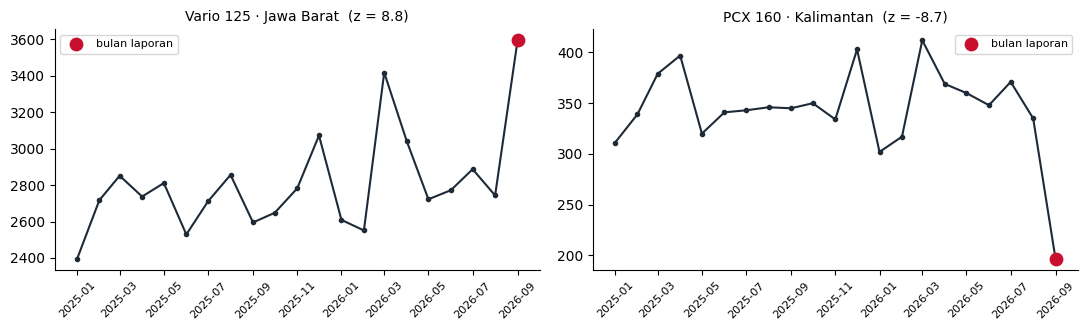

In [6]:
def deteksi_anomali(data, bulan, ambang=3.0, jendela=12):
    b = pd.Timestamp(bulan)
    lebar = lambda kolom: (data.pivot_table(index="bulan", columns=["wilayah", "model"],
                                            values=kolom, aggfunc="sum").sort_index())
    seri, target = lebar("unit"), lebar("target_unit")
    rasio = seri / target * 100                         # % pencapaian target (sudah memperhitungkan musim)
    mom = seri.pct_change() * 100                       # perubahan % dari bulan sebelumnya (untuk narasi)
    riwayat = rasio.loc[:b - pd.DateOffset(months=1)].tail(jendela)
    z = (rasio.loc[b] - riwayat.mean()) / riwayat.std()
    hasil = pd.DataFrame({"pencapaian_persen": rasio.loc[b].round(1),
                          "perubahan_mom_persen": mom.loc[b].round(1),
                          "z_score": z.round(2)})
    hasil = hasil[hasil["z_score"].abs() >= ambang].reset_index()
    return hasil.sort_values("z_score", key=abs, ascending=False), seri


anomali, seri = deteksi_anomali(data, BULAN_LAPORAN)
display(anomali)

# Visualisasi: satu anomali terhadap riwayatnya
fig, axes = plt.subplots(1, len(anomali), figsize=(11, 3.4))
for ax, (_, a) in zip(np.atleast_1d(axes), anomali.iterrows()):
    s = seri[(a["wilayah"], a["model"])]
    ax.plot(s.index, s.values, color=GELAP, marker="o", markersize=3)
    ax.scatter([s.index[-1]], [s.values[-1]], color=MERAH, s=80, zorder=3, label="bulan laporan")
    ax.set_title(f"{a['model']} · {a['wilayah']}  (z = {a['z_score']:.1f})", fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("grafik_anomali.png", dpi=150)
plt.show()

**Penjelasan kode**
- `lebar = lambda kolom: ...` — fungsi singkat (*lambda*) untuk membuat tabel lebar; dipakai dua kali (unit & target) agar kode tidak berulang.
- `pivot_table(index="bulan", columns=["wilayah", "model"])` — mengubah data panjang menjadi lebar: setiap kolom adalah satu deret waktu wilayah × model (kolom **MultiIndex**).
- `seri / target * 100` — pembagian dua tabel berukuran sama dilakukan sel-per-sel → rasio pencapaian untuk 42 deret sekaligus.
- `pct_change()` — perubahan relatif dari baris sebelumnya; disimpan untuk narasi, **bukan** untuk deteksi.
- `rasio.loc[:b - 1 bulan].tail(12)` — riwayat 12 bulan **sebelum** bulan laporan (bulan laporan tidak ikut dihitung agar anomali tidak "menyamarkan" dirinya sendiri).
- `(nilai - mean) / std` — rumus z-score, dihitung serentak untuk 42 deret.
- `sort_values("z_score", key=abs)` — mengurutkan berdasarkan **nilai absolut** z (anomali positif & negatif diperlakukan setara).
- `np.atleast_1d(axes)` — memastikan `axes` bisa diiterasi walau hanya ada satu grafik.
- `scatter(... zorder=3)` — menandai titik bulan laporan berwarna merah di atas garis.
- Hasil: dua anomali yang kita tanam terdeteksi otomatis, tanpa ada yang "memberi tahu" algoritma.

## Grafik standar laporan

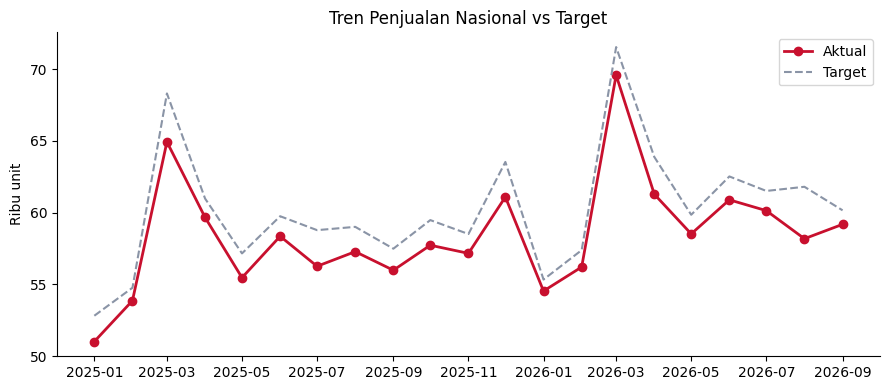

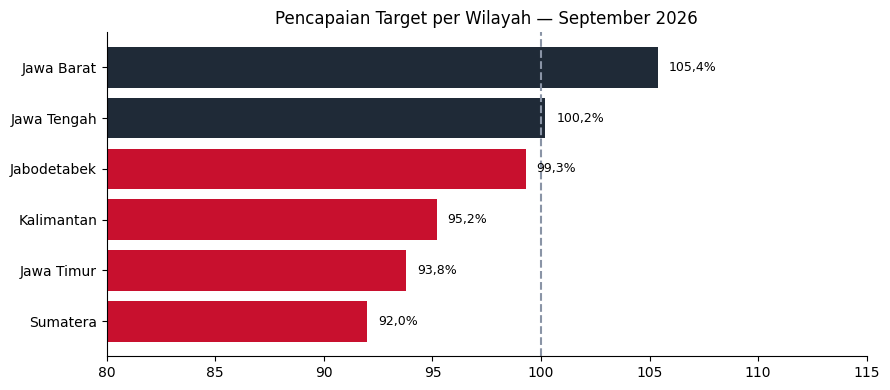

In [7]:
def buat_grafik(data, bulan, per_wilayah, folder=".", tampil=True):
    b = pd.Timestamp(bulan)
    nasional = data[data["bulan"] <= b].groupby("bulan")[["unit", "target_unit"]].sum()

    fig, ax = plt.subplots()
    ax.plot(nasional.index, nasional["unit"] / 1000, color=MERAH, marker="o", linewidth=2, label="Aktual")
    ax.plot(nasional.index, nasional["target_unit"] / 1000, color=ABU, linestyle="--", label="Target")
    ax.set_ylabel("Ribu unit")
    ax.set_title("Tren Penjualan Nasional vs Target")
    ax.legend()
    plt.tight_layout()
    f1 = os.path.join(folder, "grafik_tren.png")
    plt.savefig(f1, dpi=150)
    plt.show() if tampil else plt.close()

    fig, ax = plt.subplots()
    warna = [MERAH if v < 100 else GELAP for v in per_wilayah["pencapaian_%"]]
    ax.barh(per_wilayah.index[::-1], per_wilayah["pencapaian_%"][::-1], color=warna[::-1])
    ax.axvline(100, color=ABU, linestyle="--")
    for i, v in enumerate(per_wilayah["pencapaian_%"][::-1]):
        ax.text(v + 0.5, i, fmt_persen(v), va="center", fontsize=9)
    ax.set_xlim(80, max(115, per_wilayah["pencapaian_%"].max() + 5))
    ax.set_title(f"Pencapaian Target per Wilayah — {b:%B %Y}")
    plt.tight_layout()
    f2 = os.path.join(folder, "grafik_wilayah.png")
    plt.savefig(f2, dpi=150)
    plt.show() if tampil else plt.close()
    return f1, f2


grafik_tren, grafik_wilayah = buat_grafik(data, BULAN_LAPORAN, per_wilayah)

**Penjelasan kode**
- Grafik 1 — garis aktual vs target nasional; dibagi 1.000 agar sumbu mudah dibaca (ribu unit).
- Grafik 2 — batang horizontal pencapaian per wilayah. `warna` = merah jika < 100% (di bawah target), gelap jika tercapai: **warna membawa makna**, bukan dekorasi.
- `[::-1]` — membalik urutan agar wilayah terbaik tampil paling atas pada `barh`.
- `ax.axvline(100)` — garis referensi 100% target.
- `f"{b:%B %Y}"` — format tanggal langsung di f-string (nama bulan & tahun).
- `plt.show() if tampil else plt.close()` — parameter `tampil` menentukan grafik ditampilkan di notebook atau langsung ditutup (dipakai saat laporan dibuat otomatis).
- Fungsi mengembalikan path file PNG untuk disisipkan ke Word.

## Langkah ④ — Susun fakta (JSON) sebagai "satu-satunya sumber kebenaran"
Semua angka yang boleh muncul di narasi dikumpulkan di satu objek `fakta`. LLM hanya melihat objek ini.

In [8]:
def susun_fakta(bulan, kpi, per_wilayah, per_model, anomali):
    b = pd.Timestamp(bulan)
    nama_bulan = ["Januari", "Februari", "Maret", "April", "Mei", "Juni", "Juli",
                  "Agustus", "September", "Oktober", "November", "Desember"][b.month - 1]
    return {
        "periode": f"{nama_bulan} {b.year}",
        "kpi": kpi,
        "wilayah_terbaik": {"wilayah": per_wilayah.index[0], "pencapaian_persen": float(per_wilayah["pencapaian_%"].iloc[0])},
        "wilayah_terlemah": {"wilayah": per_wilayah.index[-1], "pencapaian_persen": float(per_wilayah["pencapaian_%"].iloc[-1])},
        "kontributor_utama": [{"model": m, "kontribusi_persen": float(r["kontribusi_%"])}
                              for m, r in per_model.head(3).iterrows()],
        "anomali": [{"wilayah": r.wilayah, "model": r.model,
                     "perubahan_mom_persen": float(r.perubahan_mom_persen), "z_score": float(r.z_score)}
                    for r in anomali.itertuples()],
    }


fakta = susun_fakta(BULAN_LAPORAN, kpi, per_wilayah, per_model, anomali)
print(json.dumps(fakta, ensure_ascii=False, indent=2))

{
  "periode": "September 2026",
  "kpi": {
    "total_unit": 59184,
    "target_unit": 60160,
    "pencapaian_target_persen": 98.4,
    "mom_persen": 1.7,
    "yoy_persen": 5.7,
    "pendapatan_miliar": 1404.2
  },
  "wilayah_terbaik": {
    "wilayah": "Jawa Barat",
    "pencapaian_persen": 105.4
  },
  "wilayah_terlemah": {
    "wilayah": "Sumatera",
    "pencapaian_persen": 92.0
  },
  "kontributor_utama": [
    {
      "model": "BeAT",
      "kontribusi_persen": 38.4
    },
    {
      "model": "Vario 125",
      "kontribusi_persen": 24.1
    },
    {
      "model": "Scoopy",
      "kontribusi_persen": 14.4
    }
  ],
  "anomali": [
    {
      "wilayah": "Jawa Barat",
      "model": "Vario 125",
      "perubahan_mom_persen": 31.0,
      "z_score": 8.82
    },
    {
      "wilayah": "Kalimantan",
      "model": "PCX 160",
      "perubahan_mom_persen": -41.5,
      "z_score": -8.7
    }
  ]
}


**Penjelasan kode**
- Nama bulan ditulis manual dalam bahasa Indonesia agar tidak bergantung pada pengaturan *locale* komputer.
- `float(...)` — mengubah angka NumPy menjadi `float` Python agar dapat di-serialisasi ke JSON.
- `per_model.head(3).iterrows()` — tiga model kontributor terbesar.
- `anomali.itertuples()` — setiap baris menjadi objek dengan atribut (`r.wilayah`, `r.z_score`).
- Struktur fakta bersarang (kpi, wilayah, model, anomali) mengikuti **struktur bab laporan** → LLM mudah memetakan fakta ke paragraf.

## Langkah ⑤ — Narasi oleh LLM + verifikasi angka otomatis
Prompt narasi memuat aturan ketat: gunakan hanya angka dari FAKTA, format Indonesia, struktur bab tetap.
Setelah itu, **verifikator** mengekstrak semua angka di narasi dan mengecek apakah setiap angka ada di fakta. Angka yang tidak dikenal = kemungkinan **halusinasi** → narasi ditahan untuk review.

In [9]:
PROMPT_NARASI = """TUGAS: NARASI_LAPORAN
PERAN: Analis Sales Planning yang menulis untuk Direksi.
TUGAS UTAMA: Tulis narasi Laporan Kinerja Penjualan dengan bagian: RINGKASAN EKSEKUTIF, KINERJA WILAYAH,
TEMUAN KHUSUS (ANOMALI), REKOMENDASI (3 butir).
BATASAN:
- Gunakan HANYA angka yang ada di FAKTA; jangan menghitung atau menambah angka baru.
- Format angka Indonesia (12.345 unit; 3,5%). Maksimal 220 kata. Nada formal & lugas.
FAKTA:
{fakta}
AKHIR_FAKTA
{ekstra}"""


def angka_dari_teks(teks):
    """Ambil semua angka berformat Indonesia dari teks → list float."""
    hasil = []
    for s in re.findall(r"\d+(?:\.\d{3})*(?:,\d+)?", teks):
        hasil.append(float(s.replace(".", "").replace(",", ".")))
    return hasil


def angka_dari_fakta(obj):
    """Ambil semua angka dari struktur fakta secara rekursif."""
    if isinstance(obj, dict):
        return [x for v in obj.values() for x in angka_dari_fakta(v)]
    if isinstance(obj, list):
        return [x for v in obj for x in angka_dari_fakta(v)]
    if isinstance(obj, (int, float)) and not isinstance(obj, bool):
        return [abs(float(obj))]
    return []


def teks_dari_fakta(obj):
    """Ambil semua nilai teks (nama wilayah, model, periode) dari fakta secara rekursif."""
    if isinstance(obj, dict):
        return [x for v in obj.values() for x in teks_dari_fakta(v)]
    if isinstance(obj, list):
        return [x for v in obj for x in teks_dari_fakta(v)]
    return [obj] if isinstance(obj, str) else []


def verifikasi_angka(narasi, fakta, toleransi=0.051):
    diizinkan = angka_dari_fakta(fakta)
    teks = narasi
    for nama in sorted(teks_dari_fakta(fakta), key=len, reverse=True):
        teks = teks.replace(nama, "")          # "Vario 125", "September 2026" bukan angka KPI
    temuan = []
    for x in angka_dari_teks(teks):
        if x <= 12 and x == int(x):                     # nomor butir/urutan (1., 2., 3.)
            continue
        ok = any(abs(x - y) <= toleransi for y in diizinkan)
        temuan.append({"angka_di_narasi": x, "ada_di_fakta": ok})
    return pd.DataFrame(temuan)


narasi = llm.generate(PROMPT_NARASI.format(fakta=json.dumps(fakta, ensure_ascii=False, indent=1), ekstra=""))
print(narasi)
cek = verifikasi_angka(narasi, fakta)
print(f"\nVerifikasi: {cek['ada_di_fakta'].sum()}/{len(cek)} angka cocok dengan fakta"
      f" → {'LOLOS' if cek['ada_di_fakta'].all() else 'TAHAN UNTUK REVIEW'}")

RINGKASAN EKSEKUTIF
Penjualan September 2026 mencapai 59.184 unit atau 98,4% dari target (di bawah target). Dibanding bulan lalu berubah +1,7%, dan dibanding periode yang sama tahun lalu +5,7%. Pendapatan tercatat Rp1.404,2 miliar.

KINERJA WILAYAH
Jawa Barat mencatat pencapaian tertinggi (105,4%), sedangkan Sumatera terendah (92,0%).

TEMUAN KHUSUS (ANOMALI)
- Vario 125 di Jawa Barat mengalami lonjakan +31,0% MoM (z-score 8,8), di luar pola normal 12 bulan terakhir.
- PCX 160 di Kalimantan mengalami penurunan tajam -41,5% MoM (z-score -8,7), di luar pola normal 12 bulan terakhir.

REKOMENDASI
1. Konfirmasi penyebab anomali ke Main Dealer terkait (stok, program, atau kendala leasing).
2. Fokuskan program penjualan di Sumatera untuk menutup gap target.
3. Replikasi praktik baik Jawa Barat ke wilayah lain.

Verifikasi: 11/11 angka cocok dengan fakta → LOLOS


**Penjelasan kode**
- `PROMPT_NARASI` — memuat **peran, struktur bab, batasan angka, format, panjang**. `{ekstra}` disediakan untuk instruksi tambahan (dipakai pada uji halusinasi).
- `angka_dari_teks()` — regex `\d+(?:\.\d{3})*(?:,\d+)?` menangkap angka format Indonesia: digit, lalu opsional kelompok `.ddd` (ribuan), lalu opsional `,d…` (desimal). Kemudian titik dihapus dan koma diganti titik agar bisa diubah ke `float`.
- `angka_dari_fakta()` — fungsi **rekursif**: jika menemukan dict/list, ia memanggil dirinya sendiri untuk isi di dalamnya; jika angka, dikembalikan dalam list. `abs()` karena narasi bisa menulis "turun 3,2%" untuk nilai −3,2.
- `not isinstance(obj, bool)` — di Python, `True` adalah turunan `int`; pengecualian ini mencegah boolean dianggap angka.
- `teks_dari_fakta()` — mengumpulkan semua teks di fakta (nama wilayah, model, periode). Sebelum angka diekstrak, teks-teks ini dihapus dari narasi, karena angka di dalam nama seperti *Vario **125*** atau *PCX **160*** bukan angka KPI. `sorted(..., key=len, reverse=True)` menghapus nama terpanjang dulu agar tidak terpotong sebagian.
- `verifikasi_angka()` — setiap angka narasi harus berada dalam toleransi 0,051 dari salah satu angka fakta (menoleransi pembulatan satu desimal). Angka kecil bulat ≤12 dilewati karena biasanya nomor butir.

In [10]:
# Uji: bagaimana jika LLM "mengarang" angka?
narasi_uji = llm.generate(PROMPT_NARASI.format(fakta=json.dumps(fakta, ensure_ascii=False), ekstra="MODE_UJI_HALUSINASI"))
cek_uji = verifikasi_angka(narasi_uji, fakta)
print("Kalimat terakhir narasi uji:", narasi_uji.splitlines()[-1])
display(cek_uji[~cek_uji["ada_di_fakta"]])
print("Status:", "LOLOS" if cek_uji["ada_di_fakta"].all() else "⛔ TAHAN UNTUK REVIEW — ada angka yang tidak bersumber dari fakta")

Kalimat terakhir narasi uji: Pangsa pasar nasional naik menjadi 78,4% dan stok dealer aman untuk 45 hari.


,angka_di_narasi,ada_di_fakta
11,78.4,False
12,45.0,False


Status: ⛔ TAHAN UNTUK REVIEW — ada angka yang tidak bersumber dari fakta


**Penjelasan kode**
- Penanda `MODE_UJI_HALUSINASI` membuat simulator menambahkan kalimat berisi angka karangan (pangsa pasar 78,4%, stok 45 hari).
- `cek_uji[~cek_uji["ada_di_fakta"]]` — menampilkan hanya angka yang **tidak** ditemukan di fakta.
- Inilah **pagar pengaman** laporan otomatis: narasi yang gagal verifikasi tidak dikirim, melainkan dikembalikan ke analis.

## Langkah ⑥ — Dokumen Word, lampiran Excel, dan draf email

In [11]:
def tulis_word(path, fakta, narasi, per_wilayah, anomali, grafik):
    doc = Document()
    gaya = doc.styles["Normal"]
    gaya.font.name, gaya.font.size = "Calibri", Pt(10.5)
    for s in doc.sections:
        s.left_margin = s.right_margin = Cm(2)

    judul = doc.add_heading(f"Laporan Kinerja Penjualan — {fakta['periode']}", level=0)
    judul.alignment = WD_ALIGN_PARAGRAPH.LEFT
    info = doc.add_paragraph("Dibuat otomatis oleh pipeline Gen AI Integrated Data Science · Status: DRAF untuk review")
    info.runs[0].font.color.rgb = RGBColor(0x8A, 0x94, 0xA6)
    info.runs[0].font.size = Pt(9)

    # Tabel KPI ringkas
    k = fakta["kpi"]
    kpi_rows = [("Total unit", fmt_angka(k["total_unit"])), ("Target unit", fmt_angka(k["target_unit"])),
                ("Pencapaian target", fmt_persen(k["pencapaian_target_persen"])),
                ("MoM", fmt_persen(k["mom_persen"], True)), ("YoY", fmt_persen(k["yoy_persen"], True)),
                ("Pendapatan", f"Rp{fmt_angka(k['pendapatan_miliar'], 1)} miliar")]
    t = doc.add_table(rows=1, cols=2, style="Light Grid Accent 2")
    t.rows[0].cells[0].text, t.rows[0].cells[1].text = "Indikator", "Nilai"
    for a, b in kpi_rows:
        sel = t.add_row().cells
        sel[0].text, sel[1].text = a, b

    # Narasi: baris HURUF BESAR → heading
    for baris in narasi.splitlines():
        if not baris.strip():
            continue
        if baris.isupper():
            doc.add_heading(baris.title(), level=1)
        elif baris.startswith("- "):
            doc.add_paragraph(baris[2:], style="List Bullet")
        else:
            doc.add_paragraph(baris)

    doc.add_heading("Grafik", level=1)
    for g in grafik:
        doc.add_picture(g, width=Cm(16))

    doc.add_heading("Lampiran: Kinerja per Wilayah", level=1)
    tw = doc.add_table(rows=1, cols=6, style="Light Grid Accent 2")
    for sel, h in zip(tw.rows[0].cells, ["Wilayah", "Unit", "Target", "Pencapaian", "MoM", "YoY"]):
        sel.text = h
    for w, r in per_wilayah.iterrows():
        nilai = [w, fmt_angka(r["unit"]), fmt_angka(r["target_unit"]), fmt_persen(r["pencapaian_%"]),
                 fmt_persen(r["mom_%"], True), fmt_persen(r["yoy_%"], True)]
        for sel, v in zip(tw.add_row().cells, nilai):
            sel.text = str(v)
    doc.save(path)
    return path


def tulis_excel(path, data, bulan, per_wilayah, per_model, anomali):
    with pd.ExcelWriter(path, engine="openpyxl") as xw:
        per_wilayah.to_excel(xw, sheet_name="Wilayah")
        per_model.to_excel(xw, sheet_name="Model")
        anomali.to_excel(xw, sheet_name="Anomali", index=False)
        data[data["bulan"] == pd.Timestamp(bulan)].to_excel(xw, sheet_name="Data_Bulan_Ini", index=False)
    return path


def draf_email(path, fakta, lampiran, penerima="direksi@contoh.co.id"):
    m = EmailMessage()
    m["Subject"] = f"[DRAF] Laporan Kinerja Penjualan {fakta['periode']}"
    m["To"], m["From"] = penerima, "sales.planning@contoh.co.id"
    k = fakta["kpi"]
    m.set_content(f"Yth. Bapak/Ibu,\n\nTerlampir laporan kinerja penjualan {fakta['periode']}. "
                  f"Penjualan {fmt_angka(k['total_unit'])} unit ({fmt_persen(k['pencapaian_target_persen'])} dari target).\n\n"
                  "Salam,\nTim Sales Planning")
    for f in lampiran:
        with open(f, "rb") as fh:
            m.add_attachment(fh.read(), maintype="application", subtype="octet-stream", filename=os.path.basename(f))
    with open(path, "wb") as fh:
        fh.write(bytes(m))
    return path


os.makedirs("laporan", exist_ok=True)
f_docx = tulis_word("laporan/Laporan_Penjualan_2026-09.docx", fakta, narasi, per_wilayah, anomali,
                    [grafik_tren, grafik_wilayah, "grafik_anomali.png"])
f_xlsx = tulis_excel("laporan/Lampiran_Penjualan_2026-09.xlsx", data, BULAN_LAPORAN, per_wilayah, per_model, anomali)
f_eml = draf_email("laporan/Draf_Email_2026-09.eml", fakta, [f_docx, f_xlsx])
for f in (f_docx, f_xlsx, f_eml):
    print(f"{f:<45} {os.path.getsize(f)/1024:>7.1f} KB")

laporan/Laporan_Penjualan_2026-09.docx          221.6 KB
laporan/Lampiran_Penjualan_2026-09.xlsx           8.6 KB
laporan/Draf_Email_2026-09.eml                  311.9 KB


**Penjelasan kode**

*`tulis_word()`*
- `Document()` — dokumen kosong; `doc.styles["Normal"]` mengatur font dasar seluruh dokumen.
- `doc.add_heading(teks, level=0)` — level 0 = judul dokumen; level 1 = judul bab.
- `doc.add_table(rows=1, cols=2, style="Light Grid Accent 2")` — tabel dengan gaya bawaan Word; `add_row().cells` menambah baris dan mengembalikan sel-selnya.
- Narasi LLM di-*parse* per baris: baris HURUF BESAR (`isupper()`) → heading, baris diawali `- ` → poin berpoin (`style="List Bullet"`), selainnya paragraf. Artinya **struktur yang kita minta di prompt langsung menjadi struktur dokumen**.
- `doc.add_picture(path, width=Cm(16))` — menyisipkan grafik PNG selebar 16 cm.

*`tulis_excel()`*
- `pd.ExcelWriter(..., engine="openpyxl")` dalam blok `with` — beberapa DataFrame ditulis ke beberapa sheet, file tersimpan saat blok selesai.

*`draf_email()`*
- `EmailMessage()` — menyusun email standar (header `Subject/To/From`, isi, lampiran). File `.eml` bisa dibuka di Outlook untuk dicek sebelum dikirim. Untuk mengirim otomatis, gunakan `smtplib.SMTP(server).send_message(m)` sesuai server email perusahaan — **setelah** status laporan disetujui.

## Satu fungsi untuk semuanya — siap dijadwalkan
Fungsi `buat_laporan_bulanan(bulan)` menjalankan keenam langkah dan mengembalikan status. Fungsi ini bisa dijalankan otomatis setiap tanggal 2 pukul 07.00 lewat **Windows Task Scheduler**, **cron** (Linux), **Power Automate**, atau *scheduler* platform data.

In [12]:
def buat_laporan_bulanan(bulan, folder="laporan"):
    t0 = time.time()
    tag = pd.Timestamp(bulan).strftime("%Y-%m")
    os.makedirs(folder, exist_ok=True)

    kpi, per_wilayah, per_model = hitung_kpi(data, bulan)                          # ②
    anomali, _ = deteksi_anomali(data, bulan)                                        # ③
    grafik = buat_grafik(data, bulan, per_wilayah, folder, tampil=False)             # grafik (tanpa tampil)
    fakta = susun_fakta(bulan, kpi, per_wilayah, per_model, anomali)                 # ④
    narasi = llm.generate(PROMPT_NARASI.format(fakta=json.dumps(fakta, ensure_ascii=False), ekstra=""))  # ⑤
    cek = verifikasi_angka(narasi, fakta)
    lolos = bool(cek["ada_di_fakta"].all())

    f_docx = tulis_word(f"{folder}/Laporan_Penjualan_{tag}.docx", fakta, narasi, per_wilayah, anomali, grafik)  # ⑥
    f_xlsx = tulis_excel(f"{folder}/Lampiran_Penjualan_{tag}.xlsx", data, bulan, per_wilayah, per_model, anomali)
    if lolos:
        draf_email(f"{folder}/Draf_Email_{tag}.eml", fakta, [f_docx, f_xlsx])
    return {"bulan": tag, "unit": kpi["total_unit"], "pencapaian_%": kpi["pencapaian_target_persen"],
            "jumlah_anomali": len(anomali), "verifikasi_angka": "LOLOS" if lolos else "TAHAN",
            "durasi_detik": round(time.time() - t0, 2)}


ringkasan_run = pd.DataFrame([buat_laporan_bulanan(b) for b in ["2026-07-01", "2026-08-01", "2026-09-01"]])
display(ringkasan_run)
print(sorted(os.listdir("laporan")))

,bulan,unit,pencapaian_%,jumlah_anomali,verifikasi_angka,durasi_detik
0,2026-07,60139,97.8,0,LOLOS,0.65
1,2026-08,58184,94.1,0,LOLOS,0.68
2,2026-09,59184,98.4,2,LOLOS,0.80


['Draf_Email_2026-07.eml', 'Draf_Email_2026-08.eml', 'Draf_Email_2026-09.eml', 'Lampiran_Penjualan_2026-07.xlsx', 'Lampiran_Penjualan_2026-08.xlsx', 'Lampiran_Penjualan_2026-09.xlsx', 'Laporan_Penjualan_2026-07.docx', 'Laporan_Penjualan_2026-08.docx', 'Laporan_Penjualan_2026-09.docx', 'grafik_tren.png', 'grafik_wilayah.png']


**Penjelasan kode**
- Nomor ②–⑥ di komentar memetakan setiap baris ke langkah alur laporan.
- `buat_grafik(..., tampil=False)` — dalam mode *batch* grafik hanya disimpan ke file lalu ditutup (`plt.close()`), tidak ditampilkan, agar memori tidak menumpuk saat fungsi dijalankan berulang.
- **Gerbang kualitas:** email hanya disiapkan jika verifikasi angka `LOLOS`; jika tidak, dokumen tetap dibuat berstatus draf untuk diperiksa analis.
- List comprehension `[buat_laporan_bulanan(b) for b in [...]]` — membuat 3 laporan bulan berbeda dalam hitungan detik; bandingkan dengan proses manual 1–2 hari per laporan.

**Contoh penjadwalan (di luar notebook):**
```bash
# cron Linux: jalankan tanggal 2 setiap bulan pukul 07.00
0 7 2 * *  /usr/bin/python3 /opt/laporan/buat_laporan.py >> /var/log/laporan.log 2>&1
```
Di Windows: *Task Scheduler → Create Basic Task → Monthly → Start a program → `python.exe buat_laporan.py`*.

## Ringkasan
| Langkah | Alat | Kunci kualitas |
|---|---|---|
| ① Tarik data | SQL / pandas | Satu sumber data resmi |
| ② KPI | pandas | Rumus baku & terdokumentasi |
| ③ Anomali | z-score | Fokus pada yang tidak biasa |
| ④ Fakta | JSON | Satu-satunya sumber angka |
| ⑤ Narasi | LLM + verifikator | Tidak ada angka tanpa sumber |
| ⑥ Distribusi | python-docx, openpyxl, email | Gerbang persetujuan manusia |

## Latihan
1. Tambahkan KPI **YTD** (*year-to-date*) ke `hitung_kpi()` dan tampilkan di tabel Word.
2. Turunkan ambang anomali menjadi 2,5. Berapa anomali yang muncul? Apakah semuanya layak dilaporkan?
3. Tambahkan bab "Kontributor Utama" ke prompt narasi dan pastikan verifikasi angka tetap `LOLOS`.
4. Ubah `draf_email` agar penerima berbeda per wilayah (mis. laporan Kalimantan ke Main Dealer Kalimantan).